In [1]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from networkx.algorithms.community import greedy_modularity_communities
from networkx.algorithms.community.quality import modularity
from networkx.algorithms.community import girvan_newman
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import math
from scipy import stats
import community as community_louvain
from networkx.algorithms import community as nx_community


### Question 1

##### (a) To compute the expected number of links for Erdos-Renyi network we use the formula
$$
\begin{equation}
\langle L \rangle = p \times L_{\text{max}}
\end{equation}
$$

where $$ L_{max} = \frac{N(N-1)}{2}$$

In [4]:
N = 5000
p = 7 * 10**(-4)
L_max = N*(N-1)/2
exp_link = p * L_max
print(f"The expected number of links is {exp_link}")

The expected number of links is 8748.25


##### (b) To check the connectivity regime we use the mean degree.

$$\text{Mean degree} = \frac{2 \times \langle L \rangle}{N}  $$

In [6]:
mean_degree = (2*exp_link)/ N
mean_degree

print(f"The mean degree is {mean_degree} and since it is more than 1, the connectivity regime is supercritical")

The mean degree is 3.4993 and since it is more than 1, the connectivity regime is supercritical


##### (c) To compute the critical link probability for the network we use the relation

$$\begin{equation} 
P_{c} = \frac{1}{N-1}
\end{equation}
$$

In [9]:
p_c = 1 / (N-1)
print(f"The critical linking probability for the network is {p_c}")

The critical linking probability for the network is 0.00020004000800160032


In [ ]:
p_c = 1 / (N-1)
print(f"The critical linking probability for the network is {p_c}")

##### (d) To determine the value of N_{cr} for which the network is exactly at criticality, we use  the relation 
$$ \begin{equation}
N_{cr} = \frac{1}{p} + 1
\end{equation}
$$

In [12]:
N_cr = (1/p)+1
print(f"The value of N_(cr) for which the network is exactly at criticality is {N_cr}")

The value of N_(cr) for which the network is exactly at criticality is 1429.5714285714287


##### (e i.) The average degree is given as 

$$\begin{equation}
\langle K_{cr} \rangle = p(N_{cr} -1) 
\end{equation}
$$



In [12]:
k_cr = p*(N_cr - 1)
print(f"The average degree of K_(cr) is {k_cr}")

The average degree of K_(cr) is 1.0


##### (ii) The expected average distance between randonly choosen node is calculated by 
$$ \begin{equation}
\langle d \rangle = N^{\frac{1}{3}}
\end{equation}
$$

In [14]:
exp_distance = N**(1/3)
print(f"The average distance between randomly choosen node is {exp_distance}")

The average distance between randomly choosen node is 17.09975946676697


##### (f) For a poisson degree distribution, to get the degree distribution we use the formula
$$\begin{equation}
p_{k} = \frac{e^{-\langle k \rangle} \times {-\langle k \rangle}^{k}}{k!}
\end{equation}
$$

In [16]:
k = list(range(0,4))
p_k = []
for i in k:
    p_k.append((np.exp(- mean_degree) * (mean_degree ** i))/math.factorial(i))
print(f" The poisson degree distribution for each k is given as follows p0: {p_k[0]}, p1: {p_k[1]}, p2: {p_k[2]}, p3: {p_k[3]}")


 The poisson degree distribution for each k is given as follows p0: 0.030218528990799652, p1: 0.10574369849750521, p2: 0.18501446207615999, p3: 0.21580703571436888


### Question 2

##### The linking probability p is given by the formula
$$\begin{equation}
p = \frac{\langle k \rangle}{N-1}
\end{equation}
$$

In [19]:
N1 = 600
mean_degrees = [0.5, 1.2, 6]
probs = []
for i in mean_degrees:
    probs.append(i/(N1-1))
print(f"The linking probabilities are as follows p0.5: {probs[0]}, p1.2: {probs[1]}, p6: {probs[2]}")

The linking probabilities are as follows p0.5: 0.0008347245409015025, p1.2: 0.002003338898163606, p6: 0.01001669449081803


##### (b) Generating the networks

In [21]:
G1 = nx.erdos_renyi_graph(N1, probs[0])
G2 = nx.erdos_renyi_graph(N1, probs[1])
G3 = nx.erdos_renyi_graph(N1, probs[2])
print(
    f"The three networks using Python and NetworkX:\n"
    f"G_1: {G1}\n"
    f"G_2: {G2}\n"
    f"G_3: {G3}"
)

The three networks using Python and NetworkX:
G_1: Graph with 600 nodes and 156 edges
G_2: Graph with 600 nodes and 349 edges
G_3: Graph with 600 nodes and 1765 edges


##### (c) Visualizing the three network using spring layout

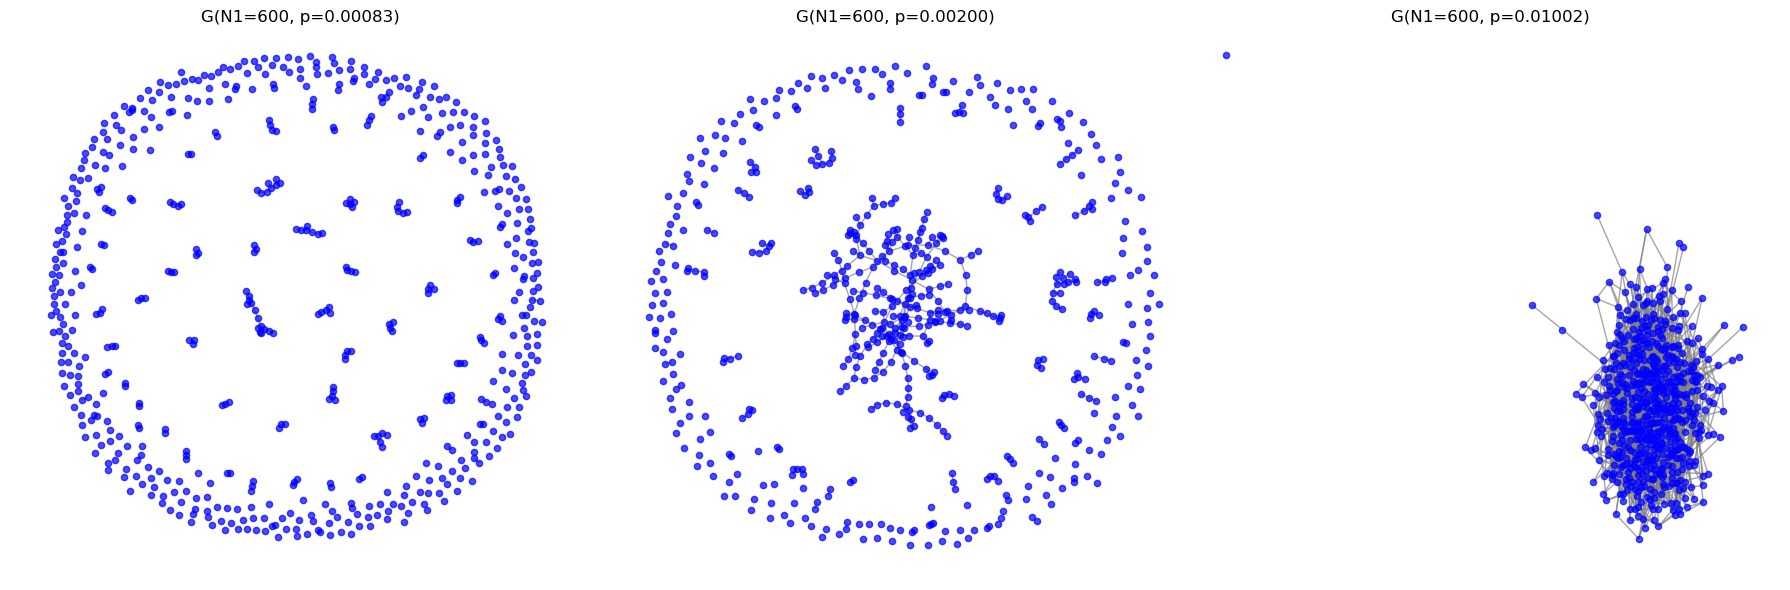

In [247]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))


orient1 = nx.spring_layout(G1, seed=42)
nx.draw(G1, pos=orient1, ax=axes[0], node_size=20, node_color='blue', edge_color='gray', alpha=0.7)
axes[0].set_title(f"G(N1={N1}, p={probs[0]:.5f})")
axes[0].axis('off')

orient2 = nx.spring_layout(G2, seed=42)
nx.draw(G2, pos=orient2, ax=axes[1], node_size=20, node_color='blue', edge_color='gray', alpha=0.7)
axes[1].set_title(f"G(N1={N1}, p={probs[1]:.5f})")
axes[1].axis('off')

orient3 = nx.spring_layout(G3, seed=42)
nx.draw(G3, pos=orient3, ax=axes[2], node_size=20, node_color='blue', edge_color='gray', alpha=0.7)
axes[2].set_title(f"G(N1={N1}, p={probs[2]:.5f})")
axes[2].axis('off')

plt.tight_layout()
plt.show()


#### (d) Discussion of each network structure

##### Subcritical


- The network is mostly tiny, disconnected components.
- item No giant component exists.
- item The graph looks fragmented, like isolated nodes and small chains.


##### Near-critical network

- The network is right at the tipping point between being mostly disconnected and forming a giant connected component.

- Component sizes vary; that is, some are small, some medium, and one large cluster is starting to appear, but is not stable yet.

- The overall structure looks irregular, almost like it is about to suddenly turn into a more connected form.

##### Supercritical networks with giant component

- A giant component appears, containing a finite fraction of all nodes.

- Remaining nodes form a small isolated component

- Connectivity becomes stronger.

- Average distances shrink.


### Question 3

##### (a) 

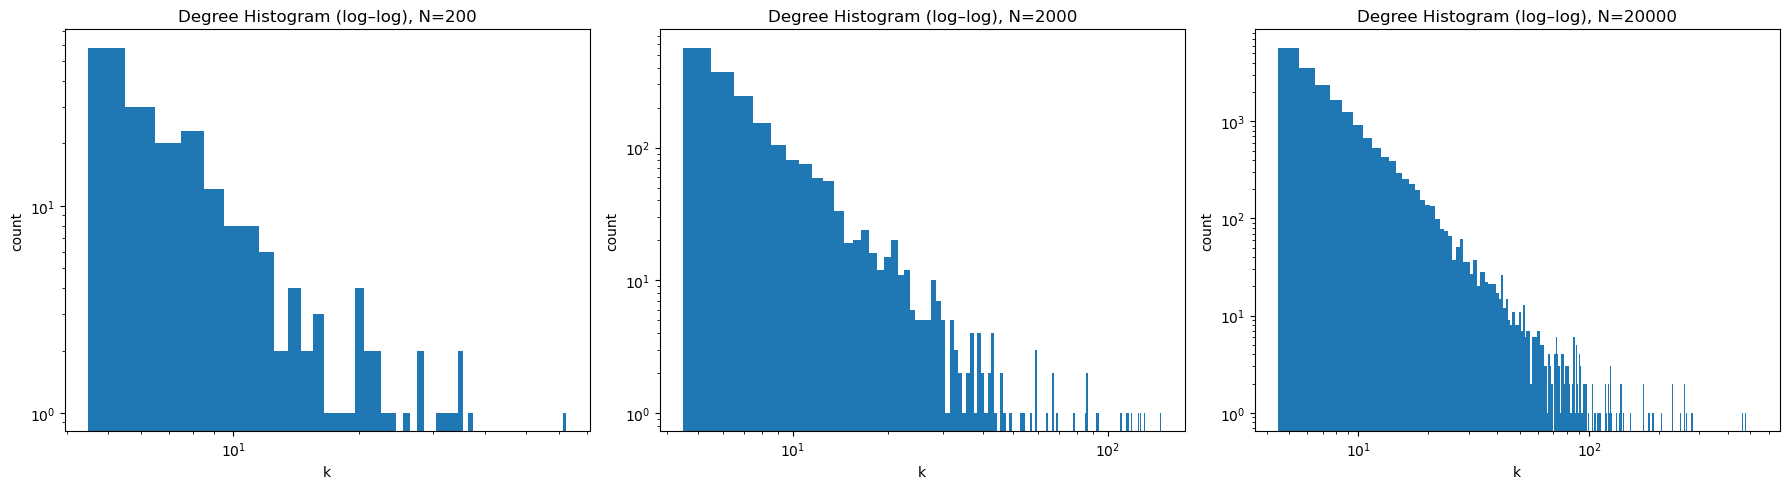

In [179]:
N2 = [200, 2000, 20000]
m = 5

graphs = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, i in zip(axes, N2):
    Gr_1 = nx.barabasi_albert_graph(i, m)
    graphs[i] = Gr_1
    degrees = [d for _, d in Gr_1.degree()]

    degree_counts = Counter(degrees)

    k_vals = np.array(sorted(degree_counts.keys()))
    counts = np.array([degree_counts[k] for k in k_vals])

    ax.bar(k_vals, counts, width=0.999)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("k")
    ax.set_ylabel("count")
    ax.set_title(f"Degree Histogram (log–log), N={i}")

plt.tight_layout()
plt.show()

##### (b) Fitting a power law to empirical distribution

In [214]:
for k in N2:
    degrees = np.array([d for _, d in graphs[k].degree()])
    degrees = degrees[degrees > 0]   

    x = np.log(np.arange(1, len(degrees) + 1))
    y = np.log(np.sort(degrees)[::-1])

    slope, intercept = np.polyfit(x, y, 1)

    beta = -slope
    gamma = 1 + 1/beta

    print(f"When N={k}: estimated degree exponent gamma ≈ {gamma:.4f}")

When N=200: estimated degree exponent gamma ≈ 2.8071
When N=2000: estimated degree exponent gamma ≈ 2.8128
When N=20000: estimated degree exponent gamma ≈ 2.8491


- As N increases, the exponent stabilizes, converging toward the theoretical  Barabasi–Albert value 3.

##### (c) Plotting a cumulative degree distribution

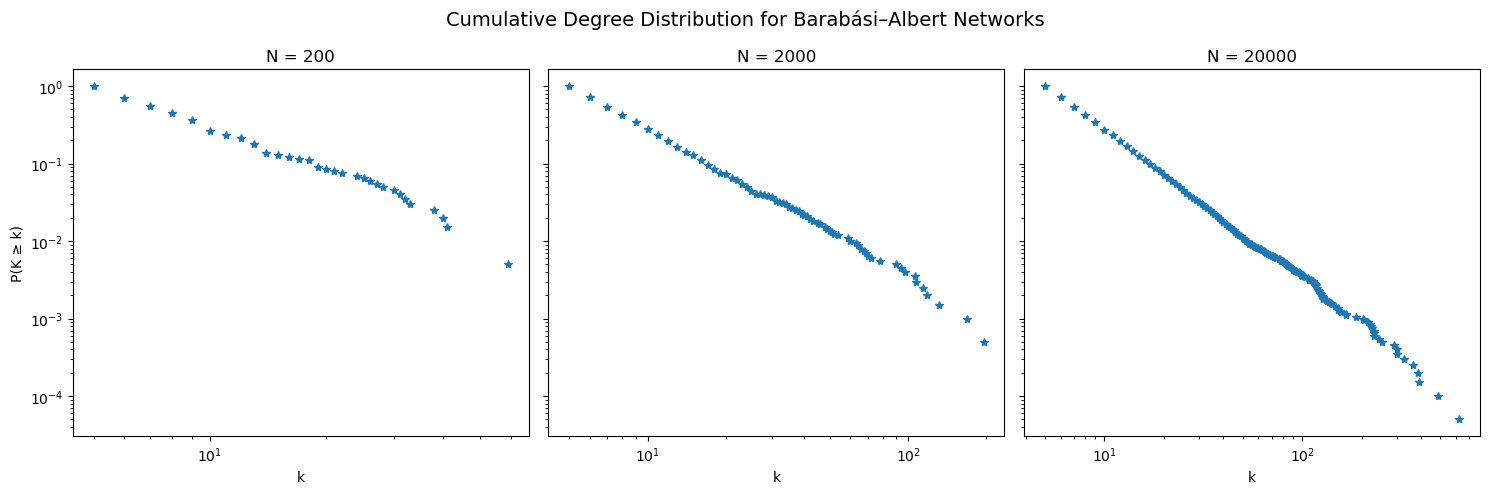

In [38]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, u in zip(axes, N2):
    G = graphs[u]

    degrees = np.array([d for _, d in G.degree()])
    degrees_sorted = np.sort(degrees)

    k_vals = np.unique(degrees_sorted)
    Pk = np.array([(degrees >= k).sum() / len(degrees) for k in k_vals])

    ax.loglog(k_vals, Pk, marker='*', linestyle='none')
    ax.set_title(f"N = {u}")
    ax.set_xlabel("k")
    #ax.grid(True, which="both", ls="--", alpha=0.4)

axes[0].set_ylabel("P(K ≥ k)")
fig.suptitle("Cumulative Degree Distribution for Barabási–Albert Networks", fontsize=14)

plt.tight_layout()
plt.show()

- The slope of the cumulative degree distribution becomes more stable as the system size increases.

- For the smallest network (N=200), the slope shows fluctuations due to finite-size effects.

-  At 𝑁=2000, these fluctuations are reduced, and the slope is closer to a straight line on the log–log plot.

- By N=20000, the slope is very stable and nearly constant over several decades of k. 

- Overall, increasing 𝑁 leads to convergence toward a common slope, indicating that the observed power-law behavior is robust.

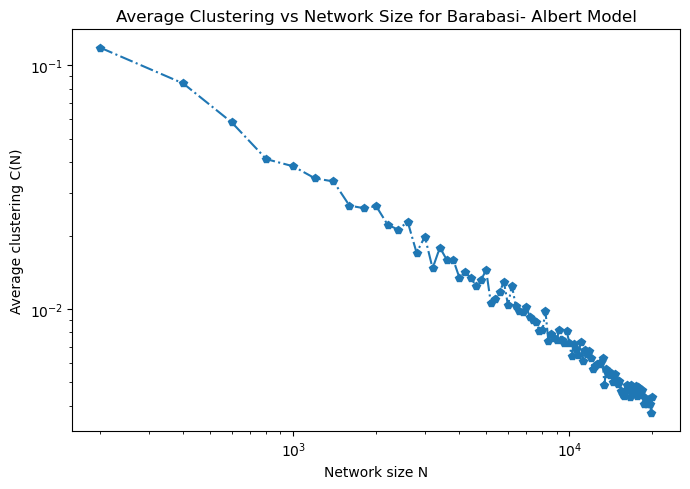

In [40]:
m = 5
N_size = np.arange(200, 20001, 200)
Clus_vals = []

for N in N_size:
    G = nx.barabasi_albert_graph(N, m)
    Clus = nx.average_clustering(G)
    Clus_vals.append(Clus)

plt.figure(figsize=(7,5))
plt.loglog(N_size, Clus_vals, marker='p', linestyle='-.')
plt.xlabel("Network size N")
plt.ylabel("Average clustering C(N)")
plt.title("Average Clustering vs Network Size for Barabasi- Albert Model")
plt.tight_layout()
plt.show()

As the Barabási–Albert network grows larger, the average clustering steadily decreases. Small networks tend to have many tightly connected groups, but as more nodes are added, these local connections become less common. The plot shows a smooth downward trend, meaning that clustering drops in a regular and predictable way as the network size increases. This indicates that the network structure becomes more tree-like and dominated by hubs, which is a known characteristic of scale-free networks.

##### (e) Measuring the degree evolution and plotting the K_i(t)

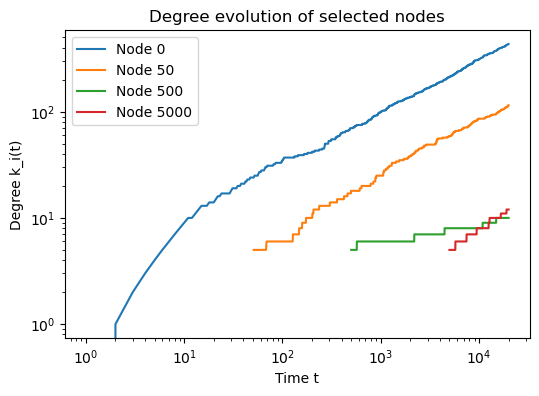

In [220]:

selected_nodes = [0, 50, 500, 5000] 
degree_evolution = {node: [] for node in selected_nodes}

for t in range(1, 20001):
    for node in selected_nodes:
        if node < t:  
            degree_evolution[node].append(G.subgraph(range(t)).degree[node])
        else:
            degree_evolution[node].append(np.nan) 


plt.figure(figsize=(6,4))
for node in selected_nodes:
    plt.plot(range(1, 20001), degree_evolution[node], label=f'Node {node}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time t')
plt.ylabel('Degree k_i(t)')
plt.title('Degree evolution of selected nodes')
plt.legend()
plt.show()





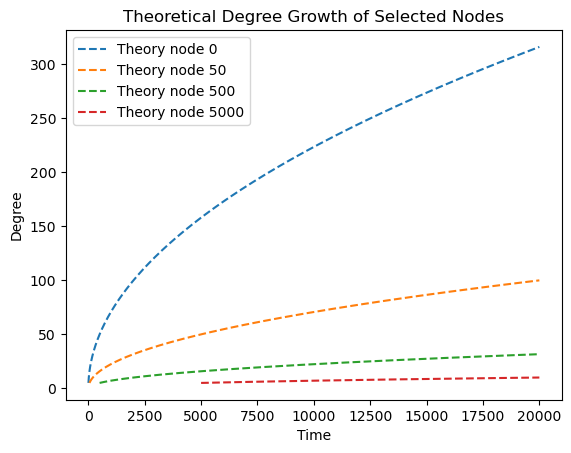

In [261]:
for node in selected_nodes:
    if node < m:
        ti = m
    else:
        ti = node

    t_vals = np.arange(ti, 20001)
    k_theory = m * np.sqrt(t_vals / ti)

    plt.plot(t_vals, k_theory, '--', label=f'Theory node {node}')
    plt.title("Theoretical Degree Growth of Selected Nodes")
plt.xlabel("Time")
plt.ylabel("Degree")
plt.legend()

### Degree Evolution and Comparison with Theory

From the empirical plots, the initial node shows the fastest degree growth and consistently maintains the highest degree over time. Nodes introduced at later times grow more slowly, and their degree curves lie progressively lower as the introduction time increases. This confirms the “first-mover advantage” inherent in preferential attachment: older nodes have more opportunities to attract new links.

On log–log axes, the empirical degree evolution curves are approximately linear, indicating power-law growth. The theoretical curves follow the same qualitative trend and closely match the empirical data, particularly at larger times. Small deviations at early times are expected due to finite-size effects and stochastic fluctuations in the attachment process.

Overall, the results are in good agreement with the theoretical prediction $$k_i(t) \sim (t/t_i)^{1/2}$$, confirming that degree growth in the Barabási–Albert model follows a square-root scaling in time and that nodes added earlier acquire links more rapidly than those added later.

##### Question 4 

##### Loading the dataset 

In [252]:
G4 = nx.read_gml("dolphins.gml")

##### (1 i.) Visualization of the dataset

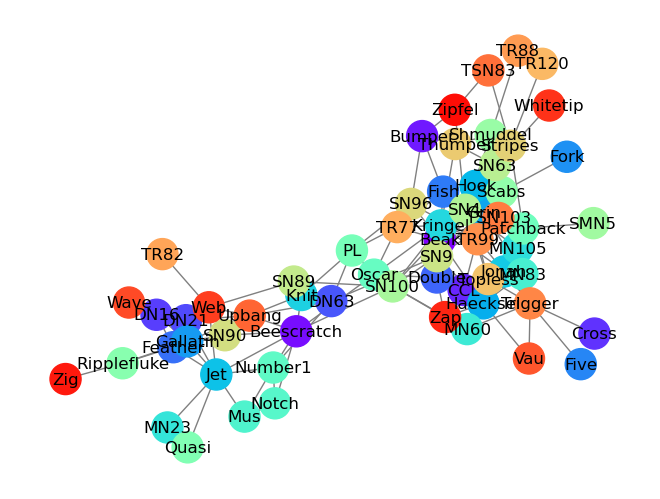

In [255]:
pos = nx.spring_layout(G4, seed=1)

number_of_dolphins = len(G4.nodes())
colors = [plt.cm.rainbow(i / number_of_dolphins) for i in range(number_of_dolphins)]

nx.draw(G4, pos, with_labels=True, node_color=colors, edge_color='gray', node_size=500)

plt.show()

##### (2) Applying tree community detection methods

##### (a) Girvan-Newman(edge betweenness)
##### Detecting the number of communities and modularity for the Girvan-Newman network

In [52]:
Gir_New = girvan_newman(G4)
communities = next(Gir_New) 
No_of_commu = len(communities)
communities= [set(c) for c in communities]
Q_greedy = modularity(G4, communities)


print(f"The number of communities is {No_of_commu}")
print(f"The modularity Q is", Q_greedy)

The number of communities is 2
The modularity Q is 0.3787033740753925


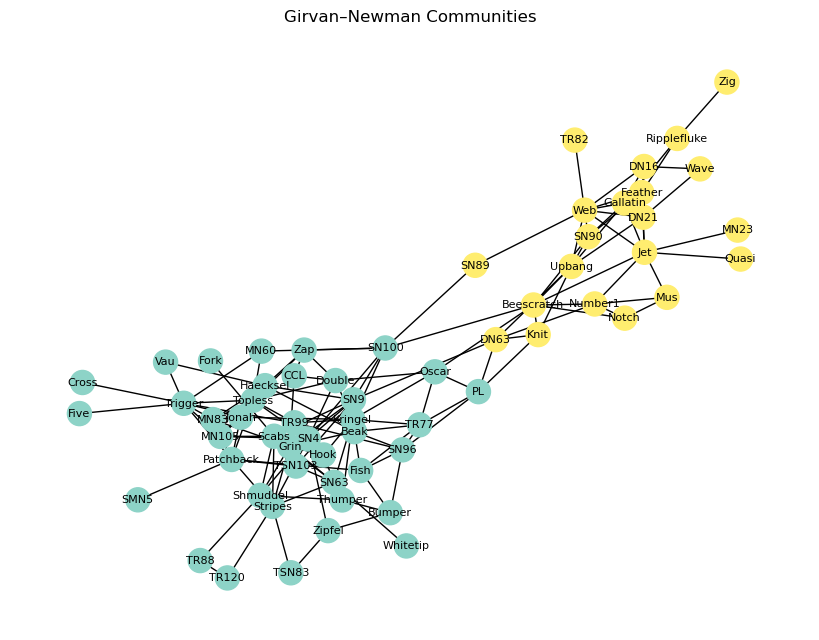

In [53]:
colors = []
for node in G4.nodes():
    for i, com in enumerate(communities):
        if node in com:
            colors.append(i)

plt.figure(figsize=(8,6))
nx.draw(G4, pos, node_color=colors, cmap=plt.cm.Set3,
        with_labels=True, node_size=300, font_size=8)
plt.title("Girvan–Newman Communities")
plt.show()

##### (b) Greedy modularity maximization.
##### Detecting the number of communities and modularity for the Greedy Modularity Maximization

In [97]:
comm_greedy = list(greedy_modularity_communities(G4))
Q_greedy = modularity(G4, comm_greedy)

print(f"The number of communities is:", len(comm_greedy))
print(f"The modularity Q is", Q_greedy)

The number of communities is: 4
The modularity Q is 0.4954906847039278


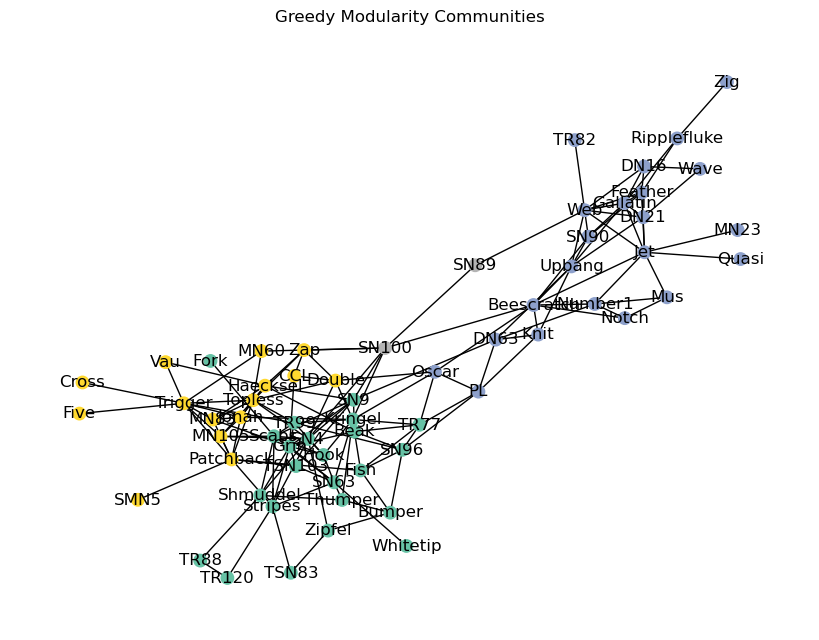

In [108]:
plt.figure(figsize=(8, 6))
colors = []
for n in G4.nodes():
    for i, c in enumerate(comm_greedy):
        if n in c:
            colors.append(i)
nx.draw(G4, pos, node_color=colors, cmap=plt.cm.Set2, node_size=80, with_labels = True)
plt.title("Greedy Modularity Communities")
plt.show()

##### (a) Louvain method
##### Detecting the number of communities and modularity(Louvain method)

In [141]:
#pip install python-louvain

In [144]:
partition = community_louvain.best_partition(G4)

communities_louvain = {}
for node, comm_id in partition.items():
    communities_louvain.setdefault(comm_id, []).append(node)

communities_louvain = list(communities_louvain.values())
Q_louvain = community_louvain.modularity(partition, G4)

print(f"The number of communities is:", len(communities_louvain))
print(f"The modularity Q is", Q_louvain)

The number of communities is: 5
The modularity Q is 0.5188283691309679


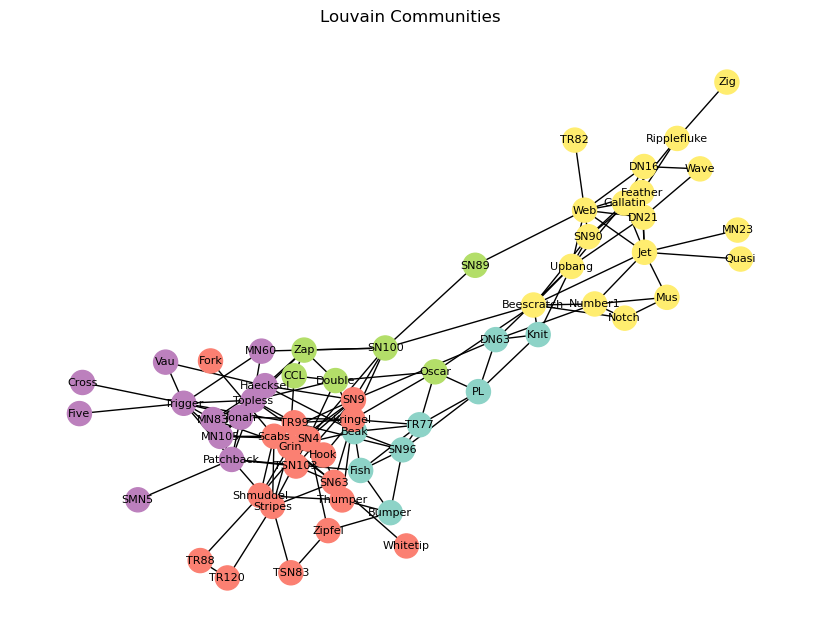

In [146]:
colors = [partition[node] for node in G4.nodes()]

plt.figure(figsize=(8,6))
nx.draw(G4, pos, node_color=colors, cmap=plt.cm.Set3,
        with_labels=True, node_size=300, font_size=8)
plt.title("Louvain Communities")
plt.show()


##### Similarities

- All detect communities: groups of nodes densely connected internally.

- All produce a partition of the network into communities.

- All can be evaluated using modularity Q.

Differences

- Girvan–Newman: The big difference is that Girvan–Newman performed significantly worse than the others, with a much lower score. It removes edges with high betweenness, is slow, and is suitable for small networks and hierarchical structures.

- Greedy Modularity: It found very precise boundaries between the dolphin groups, merges communities to maximize modularity, and it is faster.

- Louvain: It combines nodes into communities iteratively, very fast and scalable, and it produces higher modularity. It was the clear winner, finding the distinct groups most accurately.

##### (3) Comparison with the Karate Club network

In [235]:
G_karate = nx.karate_club_graph()


karate_communities = nx_community.greedy_modularity_communities(G_karate)
modularity_karate = nx_community.modularity(G_karate, karate_communities)
print("Karate Club: communities =", len(karate_communities), ", modularity =", modularity_karate)


print("Dolphins modularity (Greedy) =", Q_greedy)

Karate Club: communities = 3 , modularity = 0.4109649369389629
Dolphins modularity (Greedy) = 0.4954906847039278


The dolphins network shows a higher modularity. Networks that contain strongly connected groups with only a few links between different groups tend to have well-defined communities, which results in high modularity. In contrast, very dense networks with many connections across the whole network have less clearly separated communities and therefore lower modularity. This shows that both the network structure and its overall density influence how communities are formed.

##### (B) Toy Graph for Manuel Hierarchical Clustering

In [237]:
G = nx.Graph()
edges = [("A","B"),("A","C"),("B","C"),("C","D"),("D","E"),("E","F"),("E","G"),("F","G")]
G.add_edges_from(edges)

nodes = list(G.nodes())
dist = dict(nx.all_pairs_shortest_path_length(G))
D = np.array([[dist[u][v] for v in nodes] for u in nodes])

print(nodes)
print(f'''The distance matrix is given as
{D}''')

['A', 'B', 'C', 'D', 'E', 'F', 'G']
The distance matrix is given as
[[0 1 1 2 3 4 4]
 [1 0 1 2 3 4 4]
 [1 1 0 1 2 3 3]
 [2 2 1 0 1 2 2]
 [3 3 2 1 0 1 1]
 [4 4 3 2 1 0 1]
 [4 4 3 2 1 1 0]]


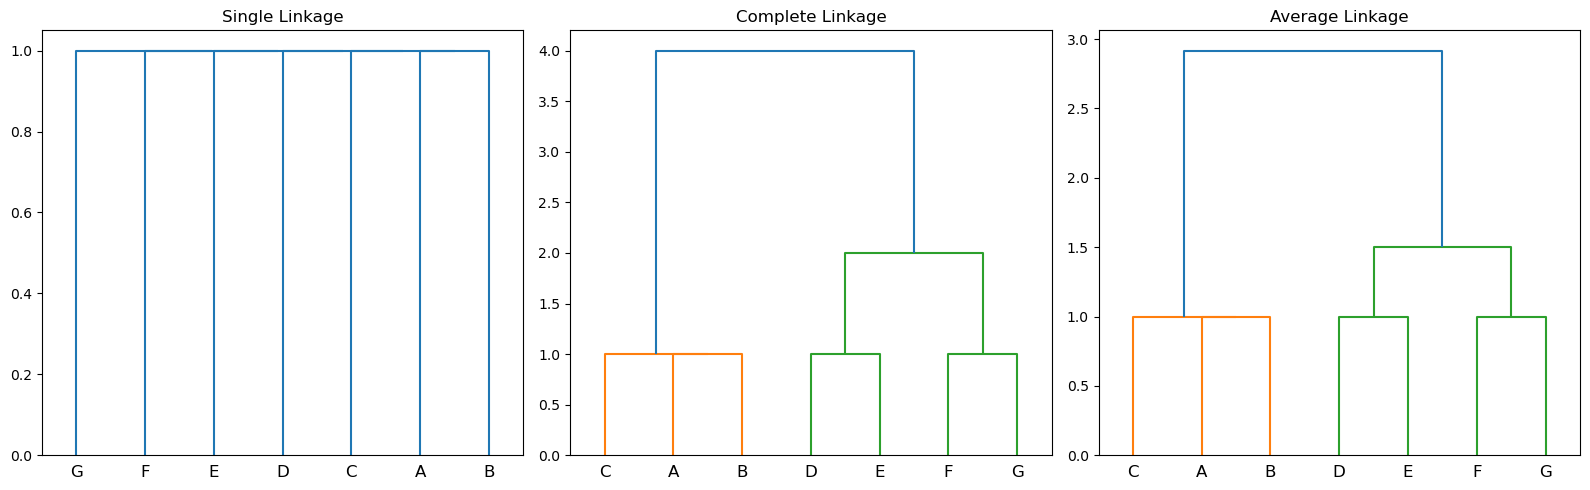

In [243]:
from scipy.spatial.distance import squareform
D_condensed = squareform(D)


Z_single = linkage(D_condensed, method="single")
Z_complete = linkage(D_condensed, method="complete")
Z_average = linkage(D_condensed, method="average")


plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
dendrogram(Z_single, labels=nodes)
plt.title("Single Linkage")

plt.subplot(1, 3, 2)
dendrogram(Z_complete, labels=nodes)
plt.title("Complete Linkage")

plt.subplot(1, 3, 3)
dendrogram(Z_average, labels=nodes)
plt.title("Average Linkage")

plt.tight_layout()
plt.show()

### 2 & 3. Hierarchical Clustering & Partitions 


#### a) Single-Linkage 
    * Merge [A,B,C] (all dist 1).
    * Merge [E,F,G] (all dist 1).
    * Link $(C,D)$ is dist 1; Link $(D,E)$ is dist 1.
    * **Result:** Because the graph is connected, **all nodes merge into a single component at distance 1**.
* **Partitions:**
* **2-Community Partition:** $\{A, B, C, D\}$ and $\{E, F, G\}$ .
* **3-Community Partition:** $\{A, B, C\}, \{D\}, \{E, F, G\}$.
* 
#### b) Complete-Linkage
1.  **Step 1 (h=1):** Form triangles $C_L = \{A,B,C\}$ and $C_R = \{E,F,G\}$. $D$ is isolated.
2.  **Step 2 (h=2):**
    * Dist($C_L, D$) = $\max(d(A,D), d(B,D), d(C,D)) = \max(2,2,1) = 2$.
    * Dist($C_R, D$) = $\max(d(E,D), d(F,D), d(G,D)) = \max(1,2,2) = 2$.
    * Merge $D$ with either side (tie). Let's merge with $C_L$. New cluster: $\{A,B,C,D\}$.
3.  **Step 3 (h=4):**
    * Dist($\{A,B,C,D\}, \{E,F,G\}$) = $\max(d(A,F)...) = 4$.
    * Final merge happens at height 4.

* **2-Community Partition:** $\{A, B, C, D\}$ and $\{E, F, G\}$ .
* **3-Community Partition:** $\{A, B, C\}, \{D\}, \{E, F, G\}$.

#### c) Average-Linkage
*Logic: Merge based on the average distance of all pairs.*
1.  **Step 1:** Form triangles $C_L$ and $C_R$.
2.  **Step 2:**
    * Avg Dist($C_L, D$) = $(d(A,D)+d(B,D)+d(C,D))/3 = (2+2+1)/3 \approx 1.67$.
    * Merge $D$ with $C_L$ (or $C_R$) at $h \approx 1.67$.
3.  **Step 3:**
    * Calculate avg dist between $\{A,B,C,D\}$ and $\{E,F,G\}$.
    * Sum of distances = 35. Total pairs = 12.
    * $h = 35/12 \approx 2.91$.

* **2-Community Partition:** $\{A, B, C, D\}$ and $\{E, F, G\}$.
* **3-Community Partition:** $\{A, B, C\}, \{D\}, \{E, F, G\}$.


### 5. Comparing Clustering Quality
* **Which linkage gives the highest modularity?**  
  Average linkage gives the highest modularity.

* **Why average linkage is better than single linkage:**  
  Single linkage joins clusters too quickly because of the *chaining effect*. It treats the bridge connection (C–D–E) as just as strong as the links inside the triangles, so everything merges early. Average linkage looks at overall distances, so it delays merging across the bridge and keeps the communities separate for longer.

* **Capturing the intuitive clusters:**  
  Complete linkage and average linkage best capture the natural structure of the graph, which consists of two dense triangles.

* **Modularity and the bridge node D:**  
  Modularity-based methods often have difficulty with bridge nodes like D. To increase the number of internal edges, modularity usually assigns D to one of the larger groups (for example, {A, B, C, D}), even though D mainly acts as a connector between communities rather than belonging clearly to either one.

In [ ]:
p_c = 1 / (N-1)
print(f"The critical linking probability for the network is {p_c}")